In [45]:
import pandas as pd
import numpy as np
import hashlib
import pandahouse
import swifter
import seaborn as sns
from scipy import stats
import matplotlib.pyplot as plt

In [12]:
def ab_split(id, salt='exp_mess_1', n_groups=5):
    test_id = str(id) + '-' + str(salt)
    test_id_digest = hashlib.md5(test_id.encode('ascii')).hexdigest()
    test_id_final_int = int(test_id_digest, 16)
    return test_id_final_int % n_groups

In [24]:
connection = {
    'host': 'http://clickhouse.lab.karpov.courses:8123',
    'password': 'dpo_python_2020',
    'user': 'student',
    'database': 'simulator_20261020'
}

q = """
SELECT distinct user_id
FROM {db}.feed_actions 
WHERE toDate(time) >= '2026-09-25' and toDate(time) <= '2026-10-01' 
"""

# все пользователи с '2026-09-25' по '2026-10-01'
users_df = pandahouse.read_clickhouse(q, connection=connection)

# хэш-группы
users_df['hash_group'] = users_df.user_id.swifter.apply(ab_split)

# кол-во пользователей в каждой хэш-группе
users_df.groupby('hash_group').user_id.nunique().reset_index()

Pandas Apply:   0%|          | 0/41997 [00:00<?, ?it/s]

,hash_group,user_id
0,0,8588
1,1,8254
2,2,8397
3,3,8305
4,4,8453


In [27]:
# эксперементальные группы 2 и 3, их лайки, просмотры и ctr
q = """
SELECT exp_group, 
    user_id,
    sum(action = 'like') as likes,
    sum(action = 'view') as views,
    likes/views as ctr
FROM {db}.feed_actions 
WHERE toDate(time) >= '2026-09-25' and toDate(time) <= '2026-10-01' 
    and exp_group in (2,3)
GROUP BY exp_group, user_id
"""

df = pandahouse.read_clickhouse(q, connection=connection)

df.groupby('exp_group').count()

,user_id,likes,views,ctr
exp_group,,,,
2,8362,8362,8362,8362
3,8425,8425,8425,8425


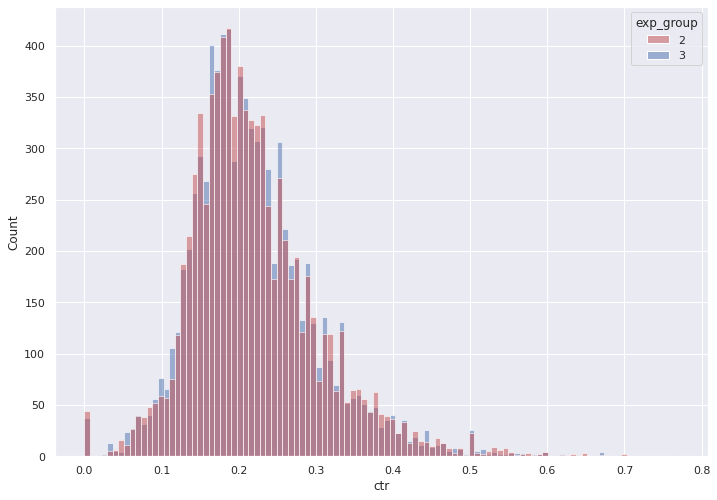

In [37]:
# график среднего ctr
sns.set(rc={'figure.figsize':(11.7,8.27)})

groups = sns.histplot(data = df, 
              x='ctr', 
              hue='exp_group', 
              palette = ['r', 'b'],
              alpha=0.5,
              kde=False)

In [49]:
def t_test(df):
    p_values = []
    for i in range(0, 10000):
        # подвыборки без возвращения размером в 500 юзеров
        group_2_sample = df[df['exp_group'] == 2].sample(n=500, replace=False)
        group_3_sample = df[df['exp_group'] == 3].sample(n=500, replace=False)
        
        # t-test
        p_values.append(stats.ttest_ind(group_2_sample.ctr, group_3_sample.ctr, equal_var=False).pvalue)
    return p_values

p_values = t_test(df)

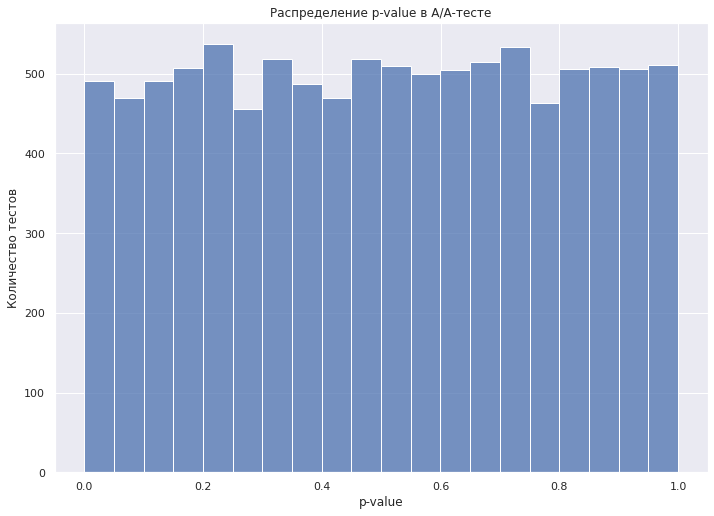

In [50]:
# гистрограмма получившихся p-value
sns.histplot(data=p_values, bins=20)
plt.xlabel('p-value')
plt.ylabel('Количество тестов')
plt.title('Распределение p-value в A/A-тесте')
plt.show()

In [57]:
# рассчет доли p-value, которые ниже порога уровня значимости
alpha = 0.05

p_values = np.array(p_values)
false_positives = np.sum(p_values < alpha)
share = false_positives / len(p_values)

print(f'Всего тестов было проведено: {len(p_values)}')
print(f'Количество ложно-положительных результатов (при alpha = 0.05): {false_positives}')
print(f'Доля долю p-value, оказавшихся ниже порога значимости в 0.05: {share}')

Всего тестов было проведено: 10000
Количество ложно-положительных результатов (при alpha = 0.05): 491
Доля долю p-value, оказавшихся ниже порога значимости в 0.05: 0.0491
